# Random Forest for IPL win probability

This notebook tunes a small set of Random Forest settings, then checks the best one against Logistic Regression. It uses the six match-state features from the current project.


In [11]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


In [12]:
DATA_CANDIDATES = [
    Path("data/processed/reduced/Final_data.csv"),
    Path("../data/processed/reduced/Final_data.csv"),
]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Can't find data/processed/reduced/Final_data.csv. Open the repo folder in VS Code.")

# Use the folder that contains the data as the project root.
PROJECT_ROOT = next(
    (
        p.resolve()
        for p in [Path.cwd(), Path.cwd().parent]
        if (p / ".git").exists()
    ),
    Path.cwd().resolve(),
)

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows across {df['match_id'].nunique():,} matches")
df.head()


Loaded 117,558 rows across 1,063 matches


,match_id,team_batting,team_bowling,current_score,season_id,match_date,city,venue,target_runs,runs_left,CRR,balls_left,RRR,wickets_left,runs_last_30,wickets_last_30,won
0,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,1,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,222,6.0,119,11.193277,10,1.0,0.0,0
1,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,2,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,221,6.0,118,11.237288,10,2.0,0.0,0
2,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,3,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,220,6.0,117,11.282051,10,3.0,0.0,0
3,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,6.0,116,11.327586,10,4.0,0.0,0
4,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,4.8,115,11.426087,10,4.0,0.0,0


## 1. Set up the data

We use seasons through 2024 to develop the model. Seasons 2025 onward are held back for a time-based check. `match_id` is only used to keep one match together during cross-validation; it is not a model feature.


In [13]:
FEATURES = ["target_runs", "runs_left", "CRR", "balls_left", "RRR", "wickets_left"]
TARGET = "won"
GROUP = "match_id"

required = FEATURES + [TARGET, GROUP, "season_id"]
assert df[required].notna().all().all(), "Required columns contain missing values."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has inconsistent outcome labels."

dev = df.loc[df["season_id"] <= 2024].reset_index(drop=True)
test = df.loc[df["season_id"] >= 2025].reset_index(drop=True)
assert not dev.empty and not test.empty, "Need both development seasons and a 2025+ holdout."
assert set(dev[GROUP]).isdisjoint(set(test[GROUP])), "A match appears in both sets."

X_dev, y_dev, groups_dev = dev[FEATURES], dev[TARGET].astype(int), dev[GROUP]
X_test, y_test = test[FEATURES], test[TARGET].astype(int)

print(f"Development: {len(dev):,} rows | {groups_dev.nunique():,} matches | through 2024")
print(f"Holdout: {len(test):,} rows | {test[GROUP].nunique():,} matches | 2025 onward")
print("Latest holdout date:", test["match_date"].max())


Development: 105,663 rows | 953 matches | through 2024
Holdout: 11,895 rows | 110 matches | 2025 onward
Latest holdout date: 2026-05-01


## 2. Tune the Random Forest

We test a small grid of tree depth, leaf size, and features considered at each split. Three match-grouped folds keep this search manageable. The best settings are chosen by **mean validation log loss** (lower is better), not by the later-season holdout.

The number of trees stays at 120 during this search to keep the run time reasonable. This is a small search, not an exhaustive one.


In [14]:
N_SPLITS = 3
N_TREES = 120
PARAM_GRID = list(ParameterGrid({
    "min_samples_leaf": [50, 100, 150],
    "max_features": ["sqrt", 1.0],
    "max_depth": [None, 12],
}))
cv = GroupKFold(n_splits=N_SPLITS)
rows = []

for candidate, params in enumerate(PARAM_GRID, start=1):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev, groups_dev), start=1):
        train_groups = set(groups_dev.iloc[train_idx])
        val_groups = set(groups_dev.iloc[val_idx])
        assert train_groups.isdisjoint(val_groups), "A match leaked across folds."

        model = RandomForestClassifier(
            n_estimators=N_TREES, n_jobs=-1, random_state=42, **params
        )
        model.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
        p_val = model.predict_proba(X_dev.iloc[val_idx])[:, 1]
        y_val = y_dev.iloc[val_idx]
        rows.append({
            "candidate": candidate,
            "fold": fold,
            "log_loss": log_loss(y_val, p_val, labels=[0, 1]),
            "brier": brier_score_loss(y_val, p_val),
            "roc_auc": roc_auc_score(y_val, p_val),
            "accuracy": accuracy_score(y_val, p_val >= 0.5),
        })
    print(f"Finished candidate {candidate}/{len(PARAM_GRID)}")

cv_results = pd.DataFrame(rows)
param_table = pd.DataFrame([
    {
        "candidate": i,
        "min_samples_leaf": p["min_samples_leaf"],
        "max_features": "all" if p["max_features"] == 1.0 else p["max_features"],
        "max_depth": "None" if p["max_depth"] is None else p["max_depth"],
    }
    for i, p in enumerate(PARAM_GRID, start=1)
]).set_index("candidate")

cv_summary = cv_results.groupby("candidate").agg(
    log_loss_mean=("log_loss", "mean"),
    log_loss_std=("log_loss", "std"),
    brier_mean=("brier", "mean"),
    roc_auc_mean=("roc_auc", "mean"),
    accuracy_mean=("accuracy", "mean"),
)
cv_summary = param_table.join(cv_summary).sort_values("log_loss_mean")
display(cv_summary.round(4))

best_candidate = int(cv_summary.index[0])
best_params = {**PARAM_GRID[best_candidate - 1], "n_estimators": N_TREES}
print("Selected settings:", best_params)


Finished candidate 1/12
Finished candidate 2/12
Finished candidate 3/12
Finished candidate 4/12
Finished candidate 5/12
Finished candidate 6/12
Finished candidate 7/12
Finished candidate 8/12
Finished candidate 9/12
Finished candidate 10/12
Finished candidate 11/12
Finished candidate 12/12


,min_samples_leaf,max_features,max_depth,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean
candidate,,,,,,,,
9,150,sqrt,12,0.4557,0.0258,0.1503,0.8659,0.7761
3,150,sqrt,None,0.4558,0.0252,0.1504,0.8658,0.7764
2,100,sqrt,None,0.4578,0.0286,0.1511,0.8647,0.7753
8,100,sqrt,12,0.4582,0.0284,0.1512,0.8643,0.7744
7,50,sqrt,12,0.4639,0.0340,0.1528,0.8618,0.7733
1,50,sqrt,None,0.4664,0.0353,0.1536,0.8605,0.7714
12,150,all,12,0.4863,0.0269,0.1549,0.8585,0.7702
6,150,all,None,0.4863,0.0269,0.1549,0.8585,0.7703
11,100,all,12,0.5072,0.0201,0.1567,0.8558,0.7665


Selected settings: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 150, 'n_estimators': 120}


## 3. Compare with Logistic Regression

Fit both models on all development seasons, then check them on the same later-season matches. We keep this holdout out of the tuning process. The dataset has only part of the 2026 season.


In [15]:
def score_probabilities(name, y_true, p):
    return {
        "model": name,
        "log_loss": log_loss(y_true, p, labels=[0, 1]),
        "brier": brier_score_loss(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "accuracy": accuracy_score(y_true, p >= 0.5),
    }

rf_final = RandomForestClassifier(n_jobs=-1, random_state=42, **best_params)
rf_final.fit(X_dev, y_dev)
p_rf = rf_final.predict_proba(X_test)[:, 1]

logreg = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
logreg.fit(X_dev, y_dev)
p_lr = logreg.predict_proba(X_test)[:, 1]

temporal_results = pd.DataFrame([
    score_probabilities("Logistic Regression", y_test, p_lr),
    score_probabilities("Random Forest", y_test, p_rf),
]).set_index("model").sort_values("log_loss")
display(temporal_results.round(4))


,log_loss,brier,roc_auc,accuracy
model,,,,
Logistic Regression,0.4244,0.1391,0.9001,0.7935
Random Forest,0.4502,0.1481,0.8901,0.7896


## 4. Check calibration

The line shows how predicted probabilities compare with actual win rates. Closer to the dashed diagonal is better.


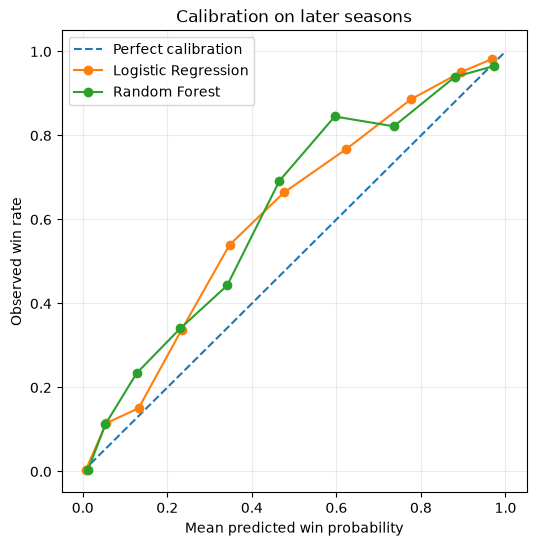

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
for name, probs in [("Logistic Regression", p_lr), ("Random Forest", p_rf)]:
    observed, predicted = calibration_curve(y_test, probs, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlabel="Mean predicted win probability", ylabel="Observed win rate",
       title="Calibration on later seasons")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 5. Feature importance

This shows which inputs the fitted forest used most. It is a useful clue, not proof that a feature causes a win.


,importance
RRR,0.4476
target_runs,0.2295
wickets_left,0.1398
runs_left,0.0945
CRR,0.0608
balls_left,0.0278


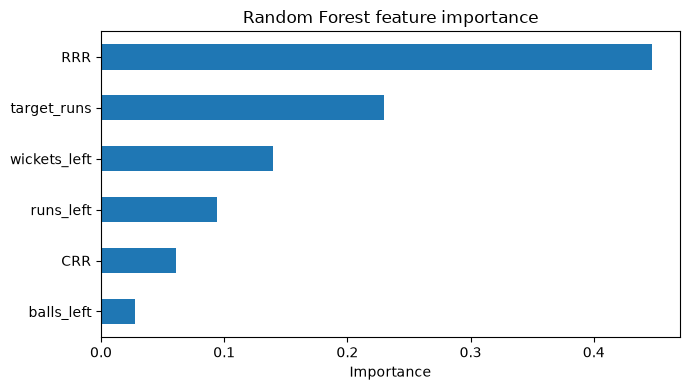

In [17]:
importance = pd.Series(rf_final.feature_importances_, index=FEATURES, name="importance")
importance = importance.sort_values(ascending=False)
display(importance.to_frame().round(4))
importance.sort_values().plot(kind="barh", figsize=(7, 4), title="Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 6. Save the results

The reports record the search, the selected settings, the later-season scores, and feature importance. They do not include the dataset or fitted model.


In [18]:
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(REPORT_DIR / "random_forest_tuning_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "random_forest_tuning_summary.csv")
temporal_results.to_csv(REPORT_DIR / "random_forest_temporal_holdout.csv")
importance.to_frame().to_csv(REPORT_DIR / "random_forest_feature_importance.csv")
with open(REPORT_DIR / "random_forest_best_params.json", "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=2)

print(f"Saved Random Forest reports to {REPORT_DIR}")


Saved Random Forest reports to C:\Users\Lenovo\Documents\IPL ML\reports
